# RF-ADC interleaving calibration on ZCU208

Hardware check and commissioning procedure for `ol.adc_cal` (`mimo_mts/drivers/adc_calibration.py`),
following PG269 *RF-ADC Calibration Mechanism*.

| Block | Corrects | After RF-ADC startup |
|---|---|---|
| OCB1 | sub-ADC offset | tracks in the background, cannot be frozen |
| OCB2 | offset, sampling-switch skew | set by foreground calibration, then frozen |
| GCB | sub-ADC gain | tracks; needs input above -40 dBFS; can be frozen |
| TSCB | sub-ADC time skew | tracks; needs input above -40 dBFS; can be frozen |

Writing coefficients enables the driver's per-block **override**: written values stay in use until
`release_override()`.

### Where to look for interleaving spurs
With M interleaved sub-ADCs, mismatch produces spurs at k·Fs/M (offset) and k·Fs/M − f_in (gain and time
skew). At Fs = 4 GHz the strongest gain/skew image is at Fs/2 − f_in, which in the 2nd Nyquist zone appears at
**6000 MHz − f_in**, i.e. mirrored about 3000 MHz.

* At f_in = **3000 MHz** that image falls exactly on the carrier, and all other spurs are ≥ 500 MHz away, outside
  the ±250 MHz band left after the RFDC decimation by 8. Calibration then has no visible effect (first run).
* At f_in = **2973 MHz** the image is at 3027 MHz, 54 MHz from the carrier and inside the band.

So the test tone is placed off 3000 MHz, and each step reports the level at the predicted spur frequencies.

### Setup
* `ALS_LLRF_ZCU208` overlay: ADC NCO 3000 MHz (2nd Nyquist zone), decimation 8 → captures at 500 MSPS.
* DAC loopback cable from a DAC to ADC `ADC_CH`; the LLRF amplitude setpoint generates the CW tone.
* Steps marked **[check]** answer open hardware questions; please keep their outputs.

In [ ]:
%cd /home/xilinx/jupyter_notebooks/pynq_llrf/

/home/xilinx/jupyter_notebooks/pynq_llrf


In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mimo_mts.overlay import MimoMtsOverlay

%load_ext autoreload
%autoreload 2

In [3]:
CONFIG = "ALS_LLRF_ZCU208"  # LLRF amplitude setpoint provides a CW tone
ADC_CH = 0  # ADC channel under test
F_CW_MHZ = 2973.0  # test tone; avoid exactly 3000 MHz (= 3 Fs/4), see above
M_SUB = 8  # assumed sub-ADC interleave factor; its spur set also covers M = 2 and 4
# Scratch file for this test. The IOCs default to /etc/mimo_mts/adc_cal.json; do not overwrite it here.
CAL_FILE = Path("/tmp/adc_cal_test.json")
N_AVG = 4  # captures averaged per spectrum
TRIG_WAIT_S = 0.6  # > one trigger period

## 1. Load overlay

In [4]:
ol = MimoMtsOverlay(config=CONFIG)
cal = ol.adc_cal
fs_hz = ol.adc_sampling_rate
fs_cap_hz = fs_hz / ol.ol_info["rfdc"]["adc_decimation_factor"]  # rate of the captured samples
print(cal)
print(f"Fs = {fs_hz / 1e9} GHz, capture rate = {fs_cap_hz / 1e6} MSPS")
print(f"ADC mixer: {ol.adc_mixer_nco_freq_mhz} MHz, Nyquist zone {ol.adc_mixer_nco_nyquist}")

LMK04828: Changing Reg 0x15f from 0x3e to 0x3b. Fix the .tcs!


Powering up and initializing analog frontend ...
<AdcCalibration: ADC channels [0, 1, 2, 3, 4, 5, 6, 7]>
Fs = 4.0 GHz, capture rate = 500.0 MSPS
ADC mixer: 3000 MHz, Nyquist zone 2


## 2. State after RF-ADC startup

First run: not frozen and `DisableFreezePin=0`, as PG269 describes.

In [5]:
print("raw CalFreeze:", cal.block(ADC_CH).CalFreeze)
print("frozen:       ", cal.is_frozen())
print("cal. mode:    ", cal.calibration_mode())
print(cal.report(ADC_CH))

raw CalFreeze: {'CalFrozen': 0, 'DisableFreezePin': 0, 'FreezeCalibration': 0}
frozen:        {0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
cal. mode:     {0: 2, 1: 2, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 2}
ADC0 (tile 0, block 0): tracking
  OCB1: [4293525441, 4290052044, 196613, 1638403, 0, 0, 0, 0]
  OCB2: [5374002, 6291508, 4259918, 6160460, 0, 0, 0, 0]
  GCB : [268369920, 0, 268308477, 267915262, 0, 0, 0, 0]
  TSCB: [33489407, 197119, 33489407, 33489407, 33489407, 33489407, 33489407, 33489407]


## 3. Trigger and CW tone (DAC loopback)

`enable_cw()` zeroes the DAC waveform buffer and uses the LLRF amplitude setpoint as a CW source, then moves the
DAC NCO so the tone is at `F_CW_MHZ`. Call it again after reloading the overlay.

The amplitude/phase loops must stay open, otherwise they react to the tone being off the 3000 MHz NCO.

In [6]:
def enable_cw(f_mhz=F_CW_MHZ):
    rm = ol.rf_control.register_map
    rm.trig_sel = 0  # internal trigger
    rm.trig_period = 125e6  # 2 Hz at 250 MHz
    rm.trig_delay = 0
    rm.trig_divide = 1
    rm.dac_enable = 1
    rm.pulse_length = 0xFFF
    ol.dac_player[:] = np.zeros(ol.dac_player.size, dtype=np.int16)
    rm.amp_loop_setpoint = 32767 / ol.rf_control.tx_gain
    rm.phs_loop_setpoint = 0
    # DAC in the 2nd Nyquist zone: NCO at -f gives a tone at +f (config uses -3000 for 3000 MHz)
    ol.dac_mixer_nco_freq_mhz = -f_mhz
    print(f"loops: amp_loop_enable={int(rm.amp_loop_enable)}, phs_loop_enable={int(rm.phs_loop_enable)}")
    print(f"DAC mixer: {ol.dac_mixer_nco_freq_mhz} MHz, Nyquist zone {ol.dac_mixer_nco_nyquist}")


enable_cw()

loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2


## 4. Spectrum and spur measurement

`expected_spurs()` lists the interleaving spurs (for `M_SUB`) that fall inside the captured band. `measure()`
reads the level at each, plus the carrier, and warns if the carrier is not where `F_CW_MHZ` puts it (wrong
frequency axis or tone setting).

In [7]:
def capture(ch=ADC_CH):
    time.sleep(TRIG_WAIT_S)
    i, q = ol.capture_adc_iq_buf()
    return i[ch].astype(np.float64) + 1j * q[ch].astype(np.float64)


def spectrum_dbfs(ch=ADC_CH, n_avg=N_AVG):
    psd = 0
    for _ in range(n_avg):
        x = capture(ch)
        win = np.blackman(len(x))
        psd = psd + np.abs(np.fft.fftshift(np.fft.fft(x * win)) / win.sum()) ** 2
    dbfs = 10 * np.log10(psd / n_avg / 32768.0**2 + 1e-30)
    f_mhz = np.fft.fftshift(np.fft.fftfreq(len(x), 1 / fs_cap_hz)) / 1e6 + ol.adc_mixer_nco_freq_mhz
    return f_mhz, dbfs


def to_rf_mhz(f_mhz):
    """Fold any frequency to the 1st Nyquist zone, then map it into the ADC's Nyquist zone."""
    fs = fs_hz / 1e6
    f = np.mod(f_mhz, fs)
    f1 = np.minimum(f, fs - f)
    zone = ol.adc_mixer_nco_nyquist
    return (zone - 1) * fs / 2 + (f1 if zone % 2 == 1 else fs / 2 - f1)


def expected_spurs(f_in=F_CW_MHZ, m=M_SUB):
    """Interleaving spurs inside the captured band: {label: RF frequency in MHz}."""
    fs = fs_hz / 1e6
    lo = ol.adc_mixer_nco_freq_mhz - 0.4 * fs_cap_hz / 1e6  # stay inside the decimation passband
    hi = ol.adc_mixer_nco_freq_mhz + 0.4 * fs_cap_hz / 1e6
    spurs = {}
    for k in range(1, m):
        for label, f in ((f"{k}Fs/{m}", k * fs / m), (f"{k}Fs/{m}-fin", k * fs / m - f_in)):
            rf = float(to_rf_mhz(f))
            if lo <= rf <= hi and abs(rf - f_in) > 1 and rf not in spurs.values():
                spurs[label] = rf
    return spurs


def level_at(f_mhz, dbfs, f0, half_width_bins=3):
    k = int(np.argmin(np.abs(f_mhz - f0)))
    sl = slice(max(0, k - half_width_bins), k + half_width_bins + 1)
    j = sl.start + int(np.argmax(dbfs[sl]))
    return f_mhz[j], dbfs[j]


def measure(label, ch=ADC_CH):
    f, d = spectrum_dbfs(ch)
    f_peak = f[int(np.argmax(d))]
    if abs(f_peak - F_CW_MHZ) > 1:
        print(f"WARNING: strongest tone at {f_peak:.3f} MHz, expected {F_CW_MHZ} MHz")
    _, carrier = level_at(f, d, F_CW_MHZ)
    row = {"carrier dBFS": round(carrier, 1)}
    print(f"--- {label}: carrier {carrier:.1f} dBFS")
    for name, f0 in expected_spurs().items():
        fm, p = level_at(f, d, f0)
        row[f"{name} @ {f0:.0f} MHz (dBc)"] = round(p - carrier, 1)
        print(f"    {name:>12s} {fm:10.3f} MHz {p:7.1f} dBFS {p - carrier:7.1f} dBc")
    table[label] = row
    spectra[label] = (f, d)


table, spectra = {}, {}
print("expected spurs in band:", expected_spurs())

expected spurs in band: {'2Fs/8': 3000.0, '4Fs/8-fin': 3027.0}


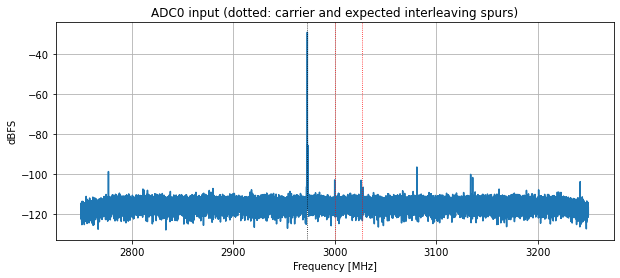

In [8]:
f, d = spectrum_dbfs()
plt.figure(figsize=(10, 4))
plt.plot(f, d)
for f0 in expected_spurs().values():
    plt.axvline(f0, color="r", ls=":", lw=0.8)
plt.axvline(F_CW_MHZ, color="k", ls=":", lw=0.8)
plt.xlabel("Frequency [MHz]")
plt.ylabel("dBFS")
plt.title(f"ADC{ADC_CH} input (dotted: carrier and expected interleaving spurs)")
plt.grid(True)

## 5. Untrained: GCB/TSCB as left by startup

Freeze immediately so the startup values are kept, and measure. This is the reference without training.

In [9]:
cal.freeze()
measure("untrained (startup)")

--- untrained (startup): carrier -28.8 dBFS
           2Fs/8   3000.000 MHz   -96.4 dBFS   -67.6 dBc
       4Fs/8-fin   3027.008 MHz  -106.7 dBFS   -77.8 dBc


## 6. Train: track the CW tone, then freeze and save

PG269 time constants are 2^20 to 2^22 samples (about 1 ms at 4 GSPS); a few seconds is plenty.

In [10]:
print(cal.unfreeze())
time.sleep(5)
measure("tracking")

{0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
--- tracking: carrier -28.8 dBFS
           2Fs/8   3000.000 MHz   -95.9 dBFS   -67.1 dBc
       4Fs/8-fin   3027.008 MHz  -109.3 dBFS   -80.4 dBc


In [11]:
print(cal.freeze())
print("raw CalFreeze:", cal.block(ADC_CH).CalFreeze)
cal.save(CAL_FILE)
measure("trained + frozen")
print(json.dumps(cal.load(CAL_FILE)[f"ADC{ADC_CH}"]["coeffs"]))

{0: True, 1: True, 2: True, 3: True, 4: True, 5: True, 6: True, 7: True}
raw CalFreeze: {'CalFrozen': 1, 'DisableFreezePin': 1, 'FreezeCalibration': 1}
--- trained + frozen: carrier -28.8 dBFS
           2Fs/8   3000.000 MHz  -104.2 dBFS   -75.4 dBc
       4Fs/8-fin   3026.993 MHz  -109.6 dBFS   -80.8 dBc
{"OCB1": [4293918665, 4290510802, 720908, 1703949, 0, 0, 0, 0], "OCB2": [5374002, 6291508, 4259918, 6160460, 0, 0, 0, 0], "GCB": [3932163, 1048609, 3473462, 6291494, 0, 0, 0, 0], "TSCB": [393248, 3407895, 4325448, 7929920, 10158198, 7274593, 5701719, 4128863]}


## 7. [check] Does a TSCB write take effect?

In the first run, GCB writes read back correctly but TSCB writes did not. The driver writes and reads the same
TSCB registers (offset `0x170`, 9-bit value, bit 15 = override enable), so the raw registers tell us:

* bit 15 set and value = written → read-back works (contradicts the first run);
* bit 15 set, value ≠ written → hardware returns the live value; the override may still act, check the spectrum;
* bit 15 clear → the write did not take.

In [12]:
def tscb_raw(ch=ADC_CH):
    """Raw TSCB registers per sub-ADC slice, via the RFDC AXI-Lite (XRFDC_BLOCK_BASE + 0x170)."""
    tile, block = cal.channels[ch]
    hs = ol.board.converters_per_tile == 2  # 4 GSPS dual-ADC tiles: 2 slices per block
    slices = [2 * block, 2 * block + 1] if hs else [block]
    out = {}
    for s in slices:
        base = 0x16000 + tile * 0x4000 + s * 0x400 + 0x170
        regs = [ol.rfdc.read(base + 4 * i) & 0xFFFF for i in range(8)]
        out[f"slice{s}"] = [f"en={r >> 15} val=0x{r & 0x1FF:03x}" for r in regs]
    return out


def pack(value):
    """Same 9-bit value for every slice of a coefficient."""
    return (value << 16 | value) if ol.board.converters_per_tile == 2 else value


print("before:", tscb_raw())
TEST = 0x010
cal.write({ADC_CH: {"TSCB": [pack(TEST)] * 8}})
print("after write 0x010:", tscb_raw())
print("driver read-back:", cal.read(ADC_CH, ["TSCB"]))
measure("TSCB = 0x010")

before: {'slice0': ['en=0 val=0x020', 'en=0 val=0x017', 'en=0 val=0x048', 'en=0 val=0x040', 'en=0 val=0x076', 'en=0 val=0x061', 'en=0 val=0x057', 'en=0 val=0x05f'], 'slice1': ['en=0 val=0x006', 'en=0 val=0x034', 'en=0 val=0x042', 'en=0 val=0x079', 'en=0 val=0x09b', 'en=0 val=0x06f', 'en=0 val=0x057', 'en=0 val=0x03f']}
after write 0x010: {'slice0': ['en=1 val=0x020', 'en=1 val=0x017', 'en=1 val=0x048', 'en=1 val=0x040', 'en=1 val=0x076', 'en=1 val=0x061', 'en=1 val=0x057', 'en=1 val=0x05f'], 'slice1': ['en=1 val=0x006', 'en=1 val=0x034', 'en=1 val=0x042', 'en=1 val=0x079', 'en=1 val=0x09b', 'en=1 val=0x06f', 'en=1 val=0x057', 'en=1 val=0x03f']}
driver read-back: {0: {'TSCB': [393248, 3407895, 4325448, 7929920, 10158198, 7274593, 5701719, 4128863]}}
--- TSCB = 0x010: carrier -28.8 dBFS
           2Fs/8   3000.000 MHz  -102.8 dBFS   -74.0 dBc
       4Fs/8-fin   3027.008 MHz  -107.4 dBFS   -78.5 dBc


## 8. Demonstrate: overwrite GCB with zeros

GCB read-back is known to work. Zeroing it (override on) should raise the gain image if the trained values matter.

In [13]:
cal.restore(CAL_FILE)
cal.write({ADC_CH: {"GCB": [0] * 8}})
measure("GCB = 0")

--- GCB = 0: carrier -28.9 dBFS
           2Fs/8   3000.000 MHz   -97.1 dBFS   -68.2 dBc
       4Fs/8-fin   3026.993 MHz   -90.4 dBFS   -61.5 dBc


## 9. Restore and verify

`restore()` writes GCB/TSCB from the file (override on), freezes, and verifies by read-back. OCB1 keeps tracking and
is not compared here.

In [14]:
print(cal.restore(CAL_FILE))
measure("restored")

{0: [], 1: [], 2: [], 3: [], 4: [], 5: [], 6: [], 7: []}
--- restored: carrier -28.8 dBFS
           2Fs/8   3000.000 MHz  -103.3 dBFS   -74.5 dBc
       4Fs/8-fin   3026.993 MHz  -105.9 dBFS   -77.1 dBc


## 10. Release override and resume tracking

In [15]:
cal.release_override()
print(cal.unfreeze())
time.sleep(5)
measure("released + tracking")

{0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
--- released + tracking: carrier -28.8 dBFS
           2Fs/8   3000.000 MHz   -98.0 dBFS   -69.2 dBc
       4Fs/8-fin   3027.008 MHz  -108.7 dBFS   -79.9 dBc


## 11. [check] Restore after a fresh overlay load

The production flow (`AlsLlrfLBL208`): load the overlay, restore, freeze. Compare with "restored" in step 9.

In [ ]:
ol.free()
ol = MimoMtsOverlay(config=CONFIG)
cal = ol.adc_cal
print("after reload, frozen:", cal.is_frozen())
enable_cw()

LMK04828: Changing Reg 0x15f from 0x3e to 0x3b. Fix the .tcs!


Powering up and initializing analog frontend ...
after reload, frozen: {0: False, 1: False, 2: False, 3: False, 4: False, 5: False, 6: False, 7: False}
loops: amp_loop_enable=0, phs_loop_enable=0
DAC mixer: -2973.0 MHz, Nyquist zone 2


In [20]:
measure("reload, untrained")
print(cal.restore(CAL_FILE))
measure("reload + restore")
print("TSCB raw:", tscb_raw())

--- reload, untrained: carrier -28.9 dBFS
           2Fs/8   3000.000 MHz  -103.3 dBFS   -74.4 dBc
       4Fs/8-fin   3026.993 MHz  -109.7 dBFS   -80.8 dBc


ADC calibration restore did not verify: {0: ['TSCB: hw=[2097180, 1900549, 4128824, 4653119, 6684786, 5898313, 4915268, 7209049] file=[393248, 3407895, 4325448, 7929920, 10158198, 7274593, 5701719, 4128863]'], 1: ['TSCB: hw=[7798789, 5701639, 8913156, 15597755, 8585538, 13762809, 14286865, 7536821] file=[1900549, 5111882, 12779603, 11075927, 14745929, 13107345, 10485941, 12779580]'], 2: ['TSCB: hw=[196697, 33488931, 1966108, 7799017, 33489407, 2884095, 33489406, 33423662] file=[196711, 31719464, 3145794, 9175123, 33489403, 5374463, 32965094, 32768495]'], 3: ['TSCB: hw=[9306269, 11075737, 11272289, 11796504, 1114118, 2228243, 2424868, 2424919] file=[8978584, 11927703, 11599973, 11468902, 851974, 786446, 2555943, 3604512]'], 4: ['TSCB: hw=[720928, 7667853, 786435, 262176, 5505074, 8257665, 2687007, 1310761] file=[3539027, 5439570, 2097195, 2031620, 4915300, 6225994, 3932285, 3145750]'], 5: ['TSCB: hw=[262211, 2424885, 6553672, 2424896, 2424904, 3473487, 7798877, 4653129] file=[196701, 465

{0: ['TSCB: hw=[2097180, 1900549, 4128824, 4653119, 6684786, 5898313, 4915268, 7209049] file=[393248, 3407895, 4325448, 7929920, 10158198, 7274593, 5701719, 4128863]'], 1: ['TSCB: hw=[7798789, 5701639, 8913156, 15597755, 8585538, 13762809, 14286865, 7536821] file=[1900549, 5111882, 12779603, 11075927, 14745929, 13107345, 10485941, 12779580]'], 2: ['TSCB: hw=[196697, 33488931, 1966108, 7799017, 33489407, 2884095, 33489406, 33423662] file=[196711, 31719464, 3145794, 9175123, 33489403, 5374463, 32965094, 32768495]'], 3: ['TSCB: hw=[9306269, 11075737, 11272289, 11796504, 1114118, 2228243, 2424868, 2424919] file=[8978584, 11927703, 11599973, 11468902, 851974, 786446, 2555943, 3604512]'], 4: ['TSCB: hw=[720928, 7667853, 786435, 262176, 5505074, 8257665, 2687007, 1310761] file=[3539027, 5439570, 2097195, 2031620, 4915300, 6225994, 3932285, 3145750]'], 5: ['TSCB: hw=[262211, 2424885, 6553672, 2424896, 2424904, 3473487, 7798877, 4653129] file=[196701, 4653119, 7995514, 2687052, 2359392, 5898319

## 12. Results

In [21]:
pd.DataFrame(table).T

,carrier dBFS,2Fs/8 @ 3000 MHz (dBc),4Fs/8-fin @ 3027 MHz (dBc)
untrained (startup),-28.8,-67.6,-77.8
tracking,-28.8,-67.1,-80.4
trained + frozen,-28.8,-75.4,-80.8
TSCB = 0x010,-28.8,-74.0,-78.5
GCB = 0,-28.9,-68.2,-61.5
restored,-28.8,-74.5,-77.1
released + tracking,-28.8,-69.2,-79.9
"reload, untrained",-28.9,-74.4,-80.8
reload + restore,-28.9,-72.1,-82.1


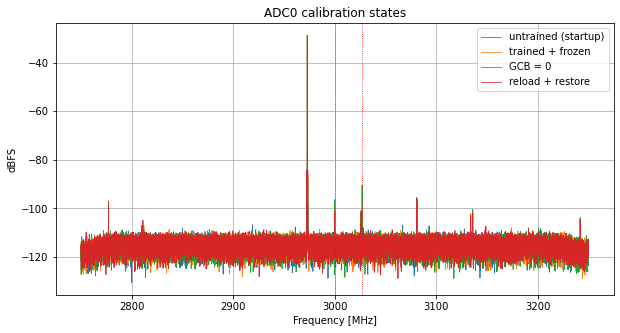

In [22]:
plt.figure(figsize=(10, 5))
for label in ("untrained (startup)", "trained + frozen", "GCB = 0", "reload + restore"):
    if label in spectra:
        plt.plot(*spectra[label], label=label, lw=0.8)
for f0 in expected_spurs().values():
    plt.axvline(f0, color="r", ls=":", lw=0.8)
plt.xlabel("Frequency [MHz]")
plt.ylabel("dBFS")
plt.title(f"ADC{ADC_CH} calibration states")
plt.legend()
plt.grid(True)

## 13. Optional: re-run foreground calibration

`restart_adc_tiles()` resets the ADC tiles (foreground calibration runs again), re-synchronizes MTS (DAC tiles are
reset too) and restores the default mixers. **Mute the input first**: PG269 requires no signal energy at k·Fs/M
during foreground calibration. First run: completed, MTS latency check passed, OCB2 recomputed, and the freeze
setting survived the reset.

In [23]:
ol.rf_control.register_map.amp_loop_setpoint = 0  # mute the CW tone
ol.rf_control.register_map.phs_loop_setpoint = 0

ol.restart_adc_tiles()
ol.check_mts_latency()
print(ol.report_mts_latency())
print("frozen after restart:", cal.is_frozen())
print(cal.report(ADC_CH))

< RFDC MTS Latency: >
  DAC Tile 0 Latency: 256, Offset: 2
  DAC Tile 1 Latency: 256, Offset: 2
  DAC Tile 2 Latency: 256, Offset: 2
  DAC Tile 3 Latency: 256, Offset: 2
  ADC Tile 0 Latency:  96, Offset: 1
  ADC Tile 1 Latency:  96, Offset: 1
  ADC Tile 2 Latency:  96, Offset: 1
  ADC Tile 3 Latency:  96, Offset: 1

frozen after restart: {0: True, 1: True, 2: True, 3: True, 4: True, 5: True, 6: True, 7: True}
ADC0 (tile 0, block 0): FROZEN
  OCB1: [4293853129, 4290445244, 917518, 1703947, 0, 0, 0, 0]
  OCB2: [7471187, 8323157, 6357102, 8257643, 0, 0, 0, 0]
  GCB : [2031619, 1310725, 1179672, 3674109, 0, 0, 0, 0]
  TSCB: [2097180, 1900549, 4128824, 4653119, 6684786, 5898313, 4915268, 7209049]
